# Full demonstration on GRB 170114A

**The input file is a POLAR collaboration product not distributed with the package.** This notebook reads `data/polarization_plus_data_170114A.root`, the GEANT4 response of GRB 170114A produced by the POLAR collaboration (Produit et al. 2018; Li et al. 2018; Kole et al. 2020), from the untracked folder `examples/data/`; place your own copy there to run it. The notebook is shipped with its stored outputs, so it can be read without the file. Expect a few minutes of runtime in total.

This is a demonstration: both response modes of the package, over the full POLAR energy grid, compared ASAD by ASAD against the GEANT4 simulations.

What the two modes need as input, in one sentence each:

- the **unpolarized-only mode** (mode 1) needs one unpolarized ASAD per energy and nothing else, and models the polarization dependence analytically;
- the **two-angle mode** (mode 2) needs, in addition, fully polarized ASADs at two polarization angles per energy, 0 and 45 degrees by default, and reads the polarization dependence from those simulations directly, so the polarization-dependent instrument effects they carry enter the response.

The chi-squared maps below follow the conventions of the paper's chi-squared map figure: energy on the horizontal axis, polarization angle on the vertical, and the diverging scale of the paper's maps, blue below one, white at one (agreement within the combined uncertainties) and vermillion above it. The overlays use the roles of the paper's figures: blue circles for the GEANT4 simulation, vermillion dashes for mode 1, bluish green dash-dots for mode 2.

Data and instrument: POLAR collaboration (Produit et al. 2018; Li et al. 2018; Kole et al. 2020). Method: the accompanying paper (Zaid et al.).

In [ ]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

from menhag import (ArrayAdapter, PolarizedBasis, ResponseConfig,
                    build_response, calculate_reduced_chi_squared, palette,
                    poisson_errors, reconstruct, reconstruct_var)
from menhag.gates import load_gate_json

palette.apply(plt)

DATA_DIR = "data"
POLAR_FILE = os.path.join(DATA_DIR, "polarization_plus_data_170114A.root")
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
assert os.path.exists(POLAR_FILE), (
    "This notebook needs the local POLAR file in examples/data/; see the "
    "note at the top.")

# The simulation normalization of these files: histograms are stored
# already divided by f = 1591. This is a property of how the input files
# were produced, supplied here as a user input; it enters ONLY the
# statistical error bars, never the counts.
NORM_FACTOR = 1591.0

DELTA, LAMBDA = 27.25, 6.07        # source direction, detector coordinates
ENERGIES = list(range(5, 751, 5))  # the full grid of the files, keV
# The stored polarization angles: the 60 simulated angles 0 to 177 degrees
# in 3 degree steps and the 180 degree entry, which repeats the 0 degree
# configuration for the closed boundary the fitting software expects.
PA_GRID = list(range(0, 181, 3))

GATE, GATE_INFO = load_gate_json("polar_gate.json")
print("gate:", GATE)

def chi2_norm(grid):
    """The diverging scale of the paper's maps: white at one, blue below,
    vermillion above, up to the maximum of the map being drawn."""
    return palette.diverging_norm(grid, center=1.0)


gate: ErfGate(mu=25.0, sigma=75.0)


In [ ]:
# Bulk-load every ASAD once: the unpolarized ASADs and the full
# GEANT4 polarized cube (150 energies x 61 stored angles x 360 bins).
import uproot

t0 = time.time()
unp = {}
g4 = np.zeros((len(ENERGIES), len(PA_GRID), 360))
with uproot.open(POLAR_FILE) as f:
    for i, e in enumerate(ENERGIES):
        vals, edges = f[f"sim_{e:03d}_000_000"].to_numpy()
        unp[e] = vals
        for j, a in enumerate(PA_GRID):
            g4[i, j] = f[f"sim_{e:03d}_100_{a:03d}"].to_numpy()[0]
EDGES = edges
g4_err = poisson_errors(g4, NORM_FACTOR)
print(f"loaded {len(ENERGIES)} unpolarized ASADs and "
      f"{g4.shape[0] * g4.shape[1]} polarized ASADs "
      f"in {time.time()-t0:.0f} s")


loaded 150 unpolarized ASADs and 9150 polarized ASADs in 3 s


## Mode 1: unpolarized-only, full grid

One `build_response` call generates the complete polarized response: 150 energies times 61 polarization angles (the 3 degree grid from 0 to 180 degrees inclusive), from the unpolarized ASADs alone, with the erf(25, 75) gate loaded from `polar_gate.json`.

In [ ]:
adapter = ArrayAdapter({
    float(e): (unp[e], EDGES, poisson_errors(unp[e], NORM_FACTOR))
    for e in ENERGIES})
config = ResponseConfig(
    energies=[float(e) for e in ENERGIES],
    delta=DELTA, lambda_=LAMBDA, threshold=GATE,
    pol_step=3, n_jobs=1,
)
t0 = time.time()
response = build_response(config, adapter)
print(f"mode 1: generated {len(response.polarized)} polarized ASADs "
      f"in {time.time()-t0:.0f} s")


mode 1: generated 9150 polarized ASADs in 12 s


### The paper's single-ASAD comparison, reproduced from the grid

Before looking at the whole grid, here is its single best-known cell: the ASAD at 150 keV and polarization angle 0, the comparison shown in the paper's single-ASAD comparison figure (same GRB, energy, source direction, gate and two-panel layout).

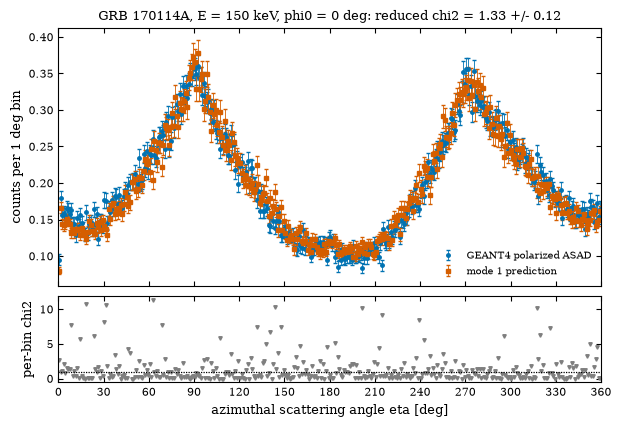

In [ ]:
eta = 0.5 * (EDGES[:-1] + EDGES[1:])
i150, j0 = ENERGIES.index(150), PA_GRID.index(0)
pred = response.polarized[(150.0, 0.0)]
chi2, chi2_err, _ = calculate_reduced_chi_squared(
    g4[i150, j0], g4_err[i150, j0], pred.counts, pred.errors, norm=NORM_FACTOR)
var = pred.counts / NORM_FACTOR + pred.errors ** 2
per_bin = np.where(var > 0, (g4[i150, j0] - pred.counts) ** 2 / var, 0.0)

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(7.0, 4.6), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.06})
ax_top.errorbar(eta, g4[i150, j0], yerr=g4_err[i150, j0], fmt=palette.mk("reference"), ms=2.5,
                color=palette.c("reference"), elinewidth=0.6, capsize=1.2,
                label="GEANT4 polarized ASAD")
ax_top.errorbar(eta, pred.counts, yerr=pred.errors, fmt=palette.mk("mode1"), ms=2.5,
                color=palette.c("mode1"), elinewidth=0.6, capsize=1.2,
                label="mode 1 prediction")
ax_top.set_ylabel("counts per 1 deg bin")
ax_top.set_title(f"GRB 170114A, E = 150 keV, phi0 = 0 deg: "
                 f"reduced chi2 = {chi2:.2f} +/- {chi2_err:.2f}")
ax_top.legend(loc="lower right", frameon=False)
ax_bot.plot(eta, per_bin, ls="none", marker=palette.mk("auxiliary"), ms=2.5,
            color=palette.c("auxiliary"))
ax_bot.axhline(1.0, color=palette.c("truth"), ls=palette.ls("truth"), lw=0.9)
ax_bot.set_xlim(0, 360)
ax_bot.xaxis.set_major_locator(plt.MultipleLocator(30))
ax_bot.set_xlabel("azimuthal scattering angle eta [deg]")
ax_bot.set_ylabel("per-bin chi2")
plt.show()
# Caption: this is the paper's single-ASAD comparison, reproduced here
# from the full response grid.


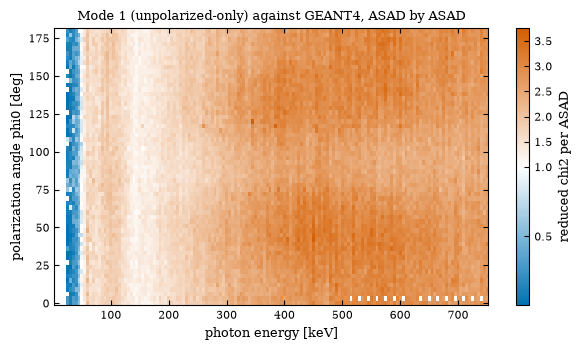

mode 1 median reduced chi2 over the grid: 2.52


In [ ]:
# Compare every generated ASAD against its GEANT4 counterpart:
# a reduced chi-squared per (energy, angle) cell, drawn with the
# diverging scale of the paper's chi-squared map figure.
chi2_grid = np.full((len(ENERGIES), len(PA_GRID)), np.nan)
for i, e in enumerate(ENERGIES):
    for j, a in enumerate(PA_GRID):
        pred = response.polarized[(float(e), float(a))]
        try:
            chi2_grid[i, j], _, _ = calculate_reduced_chi_squared(
                g4[i, j], g4_err[i, j], pred.counts, pred.errors, norm=NORM_FACTOR)
        except ValueError:
            pass    # empty simulations (closed window at the lowest energies)

fig, ax = plt.subplots(figsize=(7.0, 3.6))
im = ax.pcolormesh(ENERGIES, PA_GRID, chi2_grid.T, cmap=palette.diverging_cmap(),
                   norm=chi2_norm(chi2_grid), shading="nearest")
fig.colorbar(im, ax=ax, label="reduced chi2 per ASAD")
ax.set_xlabel("photon energy [keV]")
ax.set_ylabel("polarization angle phi0 [deg]")
ax.set_title("Mode 1 (unpolarized-only) against GEANT4, ASAD by ASAD")
plt.show()
med1 = np.nanmedian(chi2_grid)
print(f"mode 1 median reduced chi2 over the grid: {med1:.2f}")
# Caption: colour scale and orientation follow the paper's chi-squared
# map figure: white is agreement within the combined uncertainties
# (chi2 = 1), blue is below, vermillion above, up to the maximum of this
# map. The map here is on the full response grid (150 energies x 61
# stored angles) for the single GRB of this demonstration.


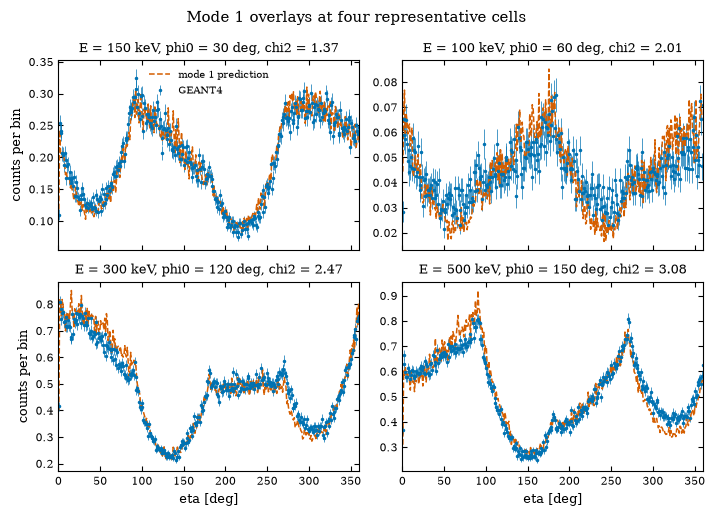

In [ ]:
# Overlays at four representative held-out cells. The paper's overlay
# figure shows the single (150 keV, 0 deg) cell, reproduced above; the
# four cells here were chosen to span the grid in energy and angle, at
# angles away from the mode 2 input angles so that the SAME cells can be
# compared for both modes below.
CELLS = [(150, 30), (100, 60), (300, 120), (500, 150)]

def overlay_cells(get_pred, role, label, title):
    fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.2), sharex=True)
    for ax, (e, a) in zip(axes.ravel(), CELLS):
        i, j = ENERGIES.index(e), PA_GRID.index(a)
        counts, errors = get_pred(e, a)
        chi2, _, _ = calculate_reduced_chi_squared(
            g4[i, j], g4_err[i, j], counts, errors, norm=NORM_FACTOR)
        ax.errorbar(eta, g4[i, j], yerr=g4_err[i, j], fmt=palette.mk("reference"), ms=1.5,
                    lw=0.5, color=palette.c("reference"), label="GEANT4")
        ax.plot(eta, counts, lw=1.1, color=palette.c(role), ls=palette.ls(role), label=label)
        ax.set_title(f"E = {e} keV, phi0 = {a} deg, chi2 = {chi2:.2f}")
        ax.set_xlim(0, 360)
    axes[0, 0].legend(frameon=False)
    for ax in axes[-1]:
        ax.set_xlabel("eta [deg]")
    for ax in axes[:, 0]:
        ax.set_ylabel("counts per bin")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

overlay_cells(
    lambda e, a: (response.polarized[(float(e), float(a))].counts,
                  response.polarized[(float(e), float(a))].errors),
    "mode1", "mode 1 prediction",
    "Mode 1 overlays at four representative cells")
# Caption: points are GEANT4, dashed lines the unpolarized-only
# predictions; the per-cell reduced chi2 is in each panel title. The same
# four cells are used for mode 2 below, so the two modes can be compared
# cell by cell.


## Mode 2: the two-angle mode

Here the polarization dependence is not modeled: it is read from two simulated polarized ASADs per energy, at 0 and 45 degrees. Per azimuthal bin the fully polarized ASAD as a function of the polarization angle is a constant plus one sinusoid in twice the angle; the unpolarized ASAD supplies the constant and the two polarized ASADs the two sinusoid coefficients, which then give every other angle.

**What held out means here.** Only the 0 and 45 degree ASADs are used to build the reconstruction; all other simulated angles are kept aside as truth and never touch the inputs. A reduced chi-squared near 1 on those held-out ASADs means agreement at the level of the simulations' own statistical noise. The two input rows of the map below are left blank on purpose: testing the reconstruction on its own inputs would prove nothing, and so is the 180 degree row, which repeats the 0 degree configuration.

mode 2: reconstructed and compared 8462 held-out ASADs in 0 s


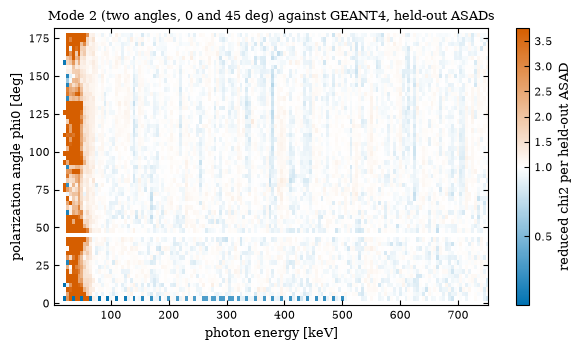

mode 1 median reduced chi2: 2.52   mode 2 median reduced chi2: 1.01


In [ ]:
BASIS_ANGLES = (0.0, 45.0)
i0, i45 = PA_GRID.index(0), PA_GRID.index(45)
basis_by_e = {}
chi2_mode2 = np.full((len(ENERGIES), len(PA_GRID)), np.nan)
t0 = time.time()
for i, e in enumerate(ENERGIES):
    basis = PolarizedBasis(
        unp[e], {0.0: g4[i, i0], 45.0: g4[i, i45]},
        var_unpolarized=poisson_errors(unp[e], NORM_FACTOR) ** 2,
        var_polarized={0.0: g4_err[i, i0] ** 2, 45.0: g4_err[i, i45] ** 2},
    )
    basis_by_e[e] = basis
    for j, a in enumerate(PA_GRID):
        if float(a) in BASIS_ANGLES or a == 180:
            continue    # inputs, and the repeated 180 degree entry
        pred = reconstruct(basis, float(a))
        perr = np.sqrt(reconstruct_var(basis, float(a)))
        try:
            chi2_mode2[i, j], _, _ = calculate_reduced_chi_squared(
                g4[i, j], g4_err[i, j], pred, perr, norm=NORM_FACTOR)
        except ValueError:
            pass
print(f"mode 2: reconstructed and compared "
      f"{np.isfinite(chi2_mode2).sum()} held-out ASADs "
      f"in {time.time()-t0:.0f} s")

fig, ax = plt.subplots(figsize=(7.0, 3.6))
im = ax.pcolormesh(ENERGIES, PA_GRID, chi2_mode2.T, cmap=palette.diverging_cmap(),
                   norm=chi2_norm(chi2_grid), shading="nearest")
fig.colorbar(im, ax=ax, label="reduced chi2 per held-out ASAD")
ax.set_xlabel("photon energy [keV]")
ax.set_ylabel("polarization angle phi0 [deg]")
ax.set_title("Mode 2 (two angles, 0 and 45 deg) against GEANT4, held-out ASADs")
plt.show()
med2 = np.nanmedian(chi2_mode2)
print(f"mode 1 median reduced chi2: {med1:.2f}   "
      f"mode 2 median reduced chi2: {med2:.2f}")
# Caption: same colour scale and orientation as the mode 1 map (the
# paper's conventions, with the shared scale set by the mode 1 maximum);
# the blank rows are the two input angles and the repeated 180 degree
# entry, excluded on purpose.


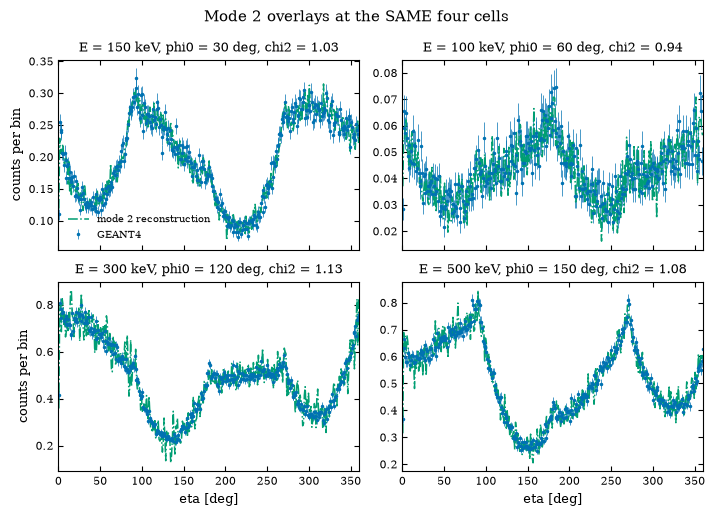

In [ ]:
overlay_cells(
    lambda e, a: (
        reconstruct(basis_by_e[e], float(a)),
        np.sqrt(reconstruct_var(basis_by_e[e], float(a)))),
    "mode2", "mode 2 reconstruction",
    "Mode 2 overlays at the SAME four cells")
# Caption: the mode 2 reconstruction (dash-dot lines) against the
# held-out GEANT4 ASAD at exactly the same four cells as the mode 1
# figure above, so the two modes compare cell by cell; the per-cell
# reduced chi2 is in each panel title.


## A finer angle grid on demand

The generated grid is a free choice. Regenerating mode 1 with `pol_step = 1` gives 181 polarization angles per energy instead of 61. The figure after the run shows what the finer grid actually provides: a full ASAD at an angle that exists only on the 1 degree grid, next to its two coarse neighbors, all computed from the same physics; nothing is interpolated.

pol_step = 1: generated 27150 ASADs in 38 s


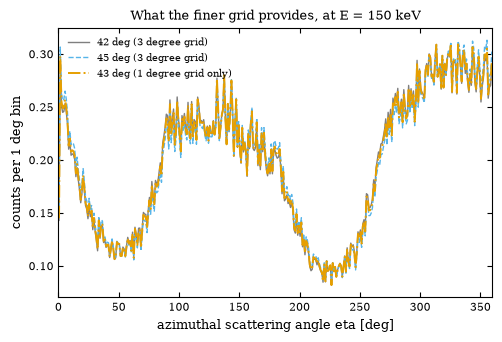

In [ ]:
config_fine = ResponseConfig(
    energies=[float(e) for e in ENERGIES],
    delta=DELTA, lambda_=LAMBDA, threshold=GATE,
    pol_step=1, n_jobs=1,
)
t0 = time.time()
response_fine = build_response(config_fine, adapter)
print(f"pol_step = 1: generated {len(response_fine.polarized)} ASADs "
      f"in {time.time()-t0:.0f} s")

E_SHOW = 150    # the energy of the paper's comparison figure
p42 = response.polarized[(float(E_SHOW), 42.0)]
p45 = response.polarized[(float(E_SHOW), 45.0)]
p43 = response_fine.polarized[(float(E_SHOW), 43.0)]

fig, ax = plt.subplots(figsize=(5.6, 3.5))
series = palette.NEUTRAL
ax.plot(eta, p42.counts, lw=1.0, color=series[0]["color"], ls=series[0]["ls"],
        label="42 deg (3 degree grid)")
ax.plot(eta, p45.counts, lw=1.0, color=series[1]["color"], ls=series[1]["ls"],
        label="45 deg (3 degree grid)")
ax.plot(eta, p43.counts, lw=1.4, color=series[2]["color"], ls=series[2]["ls"],
        label="43 deg (1 degree grid only)")
ax.set_xlim(0, 360)
ax.set_xlabel("azimuthal scattering angle eta [deg]")
ax.set_ylabel("counts per 1 deg bin")
ax.set_title(f"What the finer grid provides, at E = {E_SHOW} keV")
ax.legend(frameon=False)
plt.show()
# Caption: the 43 degree ASAD exists only on the 1 degree grid; it sits
# between its two coarse neighbors because the fine grid computes the
# ASADs between the coarse ones from the same physics. Nothing is
# interpolated. The three curves are a categorical series and carry the
# neutral styles of the paper's palette.


In [ ]:
# Save the full fine-grid response to output/ as a compact npz cube.
# The output/ folder is deliberately untracked: generated responses are
# products, not repository content.
fine_pa = list(range(0, 181))
counts = np.zeros((len(ENERGIES), len(fine_pa), 360), dtype=np.float32)
errors = np.zeros_like(counts)
for i, e in enumerate(ENERGIES):
    for j, a in enumerate(fine_pa):
        asad = response_fine.polarized[(float(e), float(a))]
        counts[i, j] = asad.counts
        errors[i, j] = asad.errors
out_path = os.path.join(OUTPUT_DIR, "170114A_response_polstep1.npz")
np.savez_compressed(out_path, energies_kev=np.array(ENERGIES),
                    pol_angles_deg=np.array(fine_pa),
                    eta_edges_deg=EDGES, counts=counts, errors=errors)
print(f"saved {out_path}: {os.path.getsize(out_path)/1e6:.0f} MB "
      f"(untracked by design)")


saved output/170114A_response_polstep1.npz: 64 MB (untracked by design)


## Closing note: from a response to a polarization measurement

The saved response is the instrument side of a polarization measurement. To fit the polarization of a burst you additionally need the event data, packaged together with the response in the style POLAR uses (an event file plus a response file consumed by the polpy plug-in for threeML); the package's `menhag.adapters.convert_prsp` writes the response part of that pair in the `.prsp` layout, in the angle order of the current polpy release by default or in that of the earlier plug-in behind the paper's fits on request (`docs/formats.md`). Other instruments adapt by writing their own small reader and writer through `menhag/adapters/template.py`, which spells out the two functions to fill in. Everything else in the chain, the physics, the kernel, the mode 2 reconstruction and the angle grids, works unchanged.